# Day 42 | Extract a Resume Into Checked JSON

**KGP Talkie**

Read every page and keep missing or uncertain fields visible.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

The supplied course uses these v1 interfaces. We keep their version notices out of the classroom display; real input, validation, and server errors still appear.

In [2]:
import warnings
warnings.filterwarnings("ignore", message=".*langchain-community.*sunset.*", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="The class `InMemoryChatMessageHistory` was deprecated.*")

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [3]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [4]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

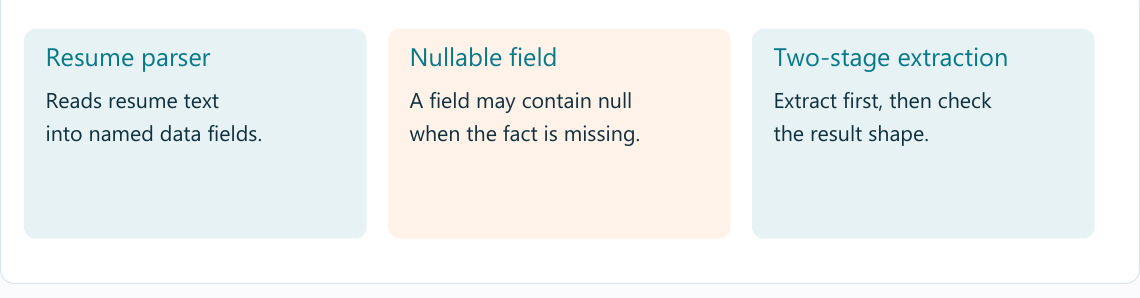

In [5]:
from langchain_community.document_loaders import PyMuPDFLoader
from pydantic import BaseModel, Field

In [6]:
docs = PyMuPDFLoader(str(ASSETS / "resume-a.pdf")).load()

Join every page. The skills are on page 2, so reading only page 1 would lose them.

In [7]:
text = "\n".join(doc.page_content for doc in docs)
print(text)

Mia
Education: BSc
City: Pune
Skills: Python, Pandas
Experience: Taught a Python workshop.


In [8]:
class Resume(BaseModel):
    name: str
    education: str | None = None
    email: str | None = Field(default=None, description="Copy an email only if the text contains one; else null")
    skills: list[str]

ChatOllama sends chat requests to the local Ollama server.

In [9]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [10]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 256-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [11]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=256, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [12]:
extract = llm.with_structured_output(Resume, method="json_schema")

First pass extracts the resume facts. The second pass puts them in our declared schema.

In [13]:
draft = llm.invoke("Extract name, education, email, and skills. If email is absent, state missing. Copy only source facts.\n" + text).content
print(draft)

Here are the extracted information:

- Name: Mia
- Education: BSc
- Email: Missing
- Skills: Python, Pandas


In [14]:
result = extract.invoke("Format these resume facts. For a missing email use JSON null, never the word None or a made-up address.\n" + draft)
result.model_dump()

{'name': 'Mia',
 'education': 'BSc',
 'email': None,
 'skills': ['Python', 'Pandas']}

The raw output stays visible above. This source check prevents saving an invented or word-only email. It does not repair other facts.

In [15]:
if result.email is not None and ("@" not in result.email or result.email not in text):
    print("Source check: model email is not in the resume. Keeping it missing.")
    result.email = None

In [16]:
print("Matches known sample:", result.model_dump() == {"name": "Mia", "education": "BSc", "email": None, "skills": ["Python", "Pandas"]})

Matches known sample: True


In [17]:
(OUTPUT / "resume-a.json").write_text(result.model_dump_json(indent=2), encoding="utf-8")

104

In [18]:
fresh_text = "\n".join(doc.page_content for doc in PyMuPDFLoader(str(ASSETS / "resume-b.pdf")).load())

In [19]:
fresh = extract.invoke("Copy only stated facts from this resume. Do not infer missing values.\n" + fresh_text)
fresh.model_dump()

{'name': 'Ravi', 'education': 'BA', 'email': None, 'skills': ['Excel']}

In [20]:
(OUTPUT / "resume-b.json").write_text(fresh.model_dump_json(indent=2), encoding="utf-8")

89

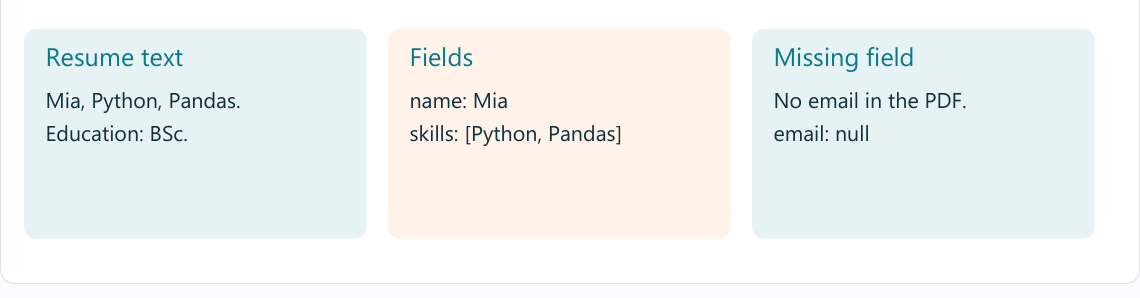

## Try a fresh input

Parse a second resume with different skills. Save both results under separate names and compare with their PDFs.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-resume-parsing).